# Bussines Understanding
Ecommerce company based in New York City that sells clothing online but also have in-store style and clothing advice sessions. Customers come in to the store, have sessions/meetings with a personal stylist, then they can go home and order either on a mobila app or website for the clothes they want.

The company is trying to decide whether to focus their efforts on their mobile app experience or their website.

# Data Import

### Import tools

In [1]:
# EDA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
# Preprocessing
from sklearn.model_selection import train_test_split
# Modeling
from sklearn.linear_model import LinearRegression
# Model Evaluation
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error

### Import dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
df = pd.read_csv('/content/drive/MyDrive/Projects/Datasets/Ecommerce Customers')

# Data Understanding

### Exploratory Data Analysis

In [4]:
df.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\nCobbborough, D...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\nPort Jason, OH 22070-1220",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\nPort Jacobville, PR 3...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [5]:
df.columns

Index(['Email', 'Address', 'Avatar', 'Avg. Session Length', 'Time on App',
       'Time on Website', 'Length of Membership', 'Yearly Amount Spent'],
      dtype='object')

In [6]:
df.shape

(500, 8)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [8]:
df.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


In [9]:
df.isna().sum()

,0
Email,0
Address,0
Avatar,0
Avg. Session Length,0
Time on App,0
Time on Website,0
Length of Membership,0
Yearly Amount Spent,0


In [10]:
df.duplicated().sum()

np.int64(0)

#### Data Visualisation

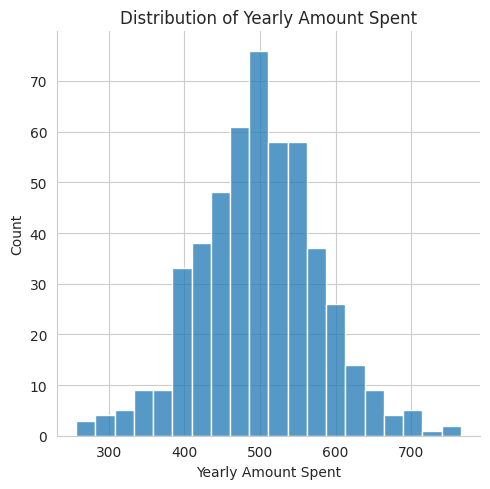

In [11]:
sns.displot(data=df, x='Yearly Amount Spent')
plt.title('Distribution of Yearly Amount Spent')
plt.tight_layout()

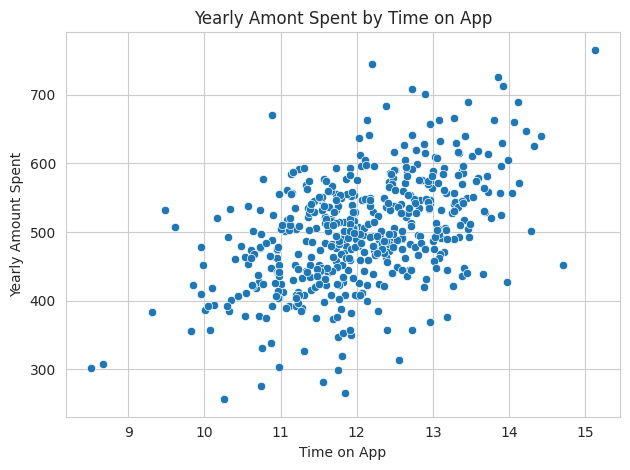

In [12]:
sns.scatterplot(data=df, x='Time on App', y='Yearly Amount Spent')
plt.title('Yearly Amont Spent by Time on App')
plt.tight_layout()

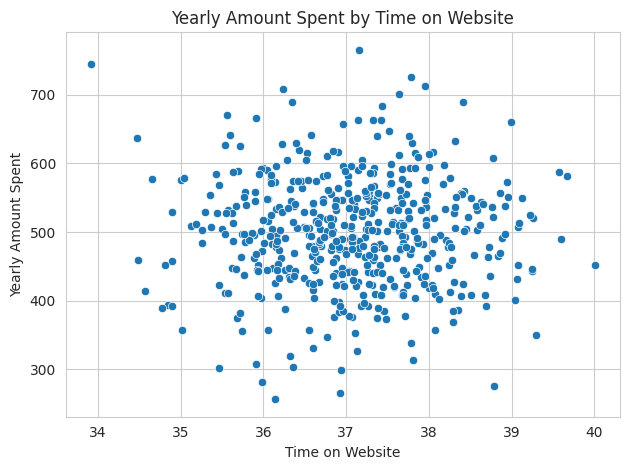

In [13]:
sns.scatterplot(data=df, x='Time on Website', y='Yearly Amount Spent')
plt.title('Yearly Amount Spent by Time on Website')
plt.tight_layout()

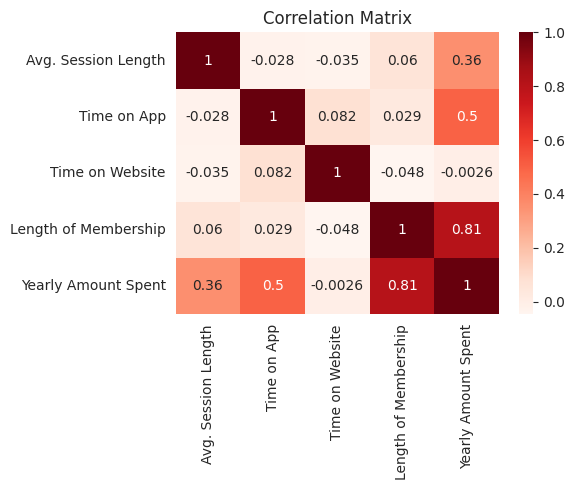

In [14]:
plt.figure(figsize=(6,5))
sns.heatmap(df.corr(numeric_only=True), cmap='Reds', annot=True)
plt.title('Correlation Matrix')
plt.tight_layout()

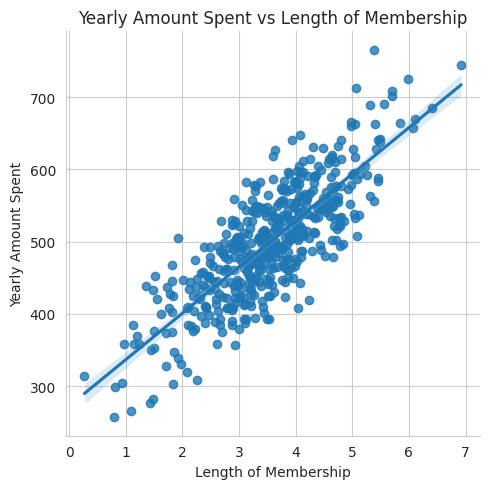

In [15]:
sns.lmplot(data=df, x='Length of Membership', y='Yearly Amount Spent')
plt.title('Yearly Amount Spent vs Length of Membership')
plt.tight_layout()

# Data Preprocessing

### Splitting data to X and y

In [16]:
X = df[['Avg. Session Length', 'Time on App', 'Time on Website', 'Length of Membership']]
y = df['Yearly Amount Spent']

In [17]:
X.head()

,Avg. Session Length,Time on App,Time on Website,Length of Membership
0,34.497268,12.655651,39.577668,4.082621
1,31.926272,11.109461,37.268959,2.664034
2,33.000915,11.330278,37.110597,4.104543
3,34.305557,13.717514,36.721283,3.120179
4,33.330673,12.795189,37.536653,4.446308


In [18]:
y.head()

,Yearly Amount Spent
0,587.951054
1,392.204933
2,487.547505
3,581.852344
4,599.406092


### Splitting data for training and testing

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Modeling

In [20]:
model = LinearRegression()
model.fit(X_train, y_train)
print('Training Score:',model.score(X_train, y_train))

Training Score: 0.9854240629700333


# Model Evaluation

### Predicting test data

In [21]:
y_pred = model.predict(X_test)

### Actual data vs Prediction data

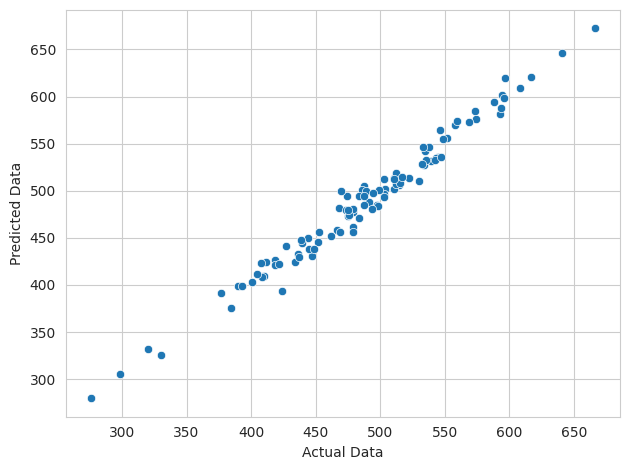

In [26]:
sns.scatterplot(x=y_test,y=y_pred)
plt.xlabel('Actual Data')
plt.ylabel('Predicted Data')
plt.tight_layout()

### Regression Metrics

In [23]:
print('Mean Absolute Error:',mean_absolute_error(y_test, y_pred))
print('Mean Squared Error:',mean_squared_error(y_test, y_pred))
print('Root Mean Squared Error:',root_mean_squared_error(y_test, y_pred))

Mean Absolute Error: 8.558441885315231
Mean Squared Error: 109.8637411839399
Root Mean Squared Error: 10.48159058463647


### Residuals

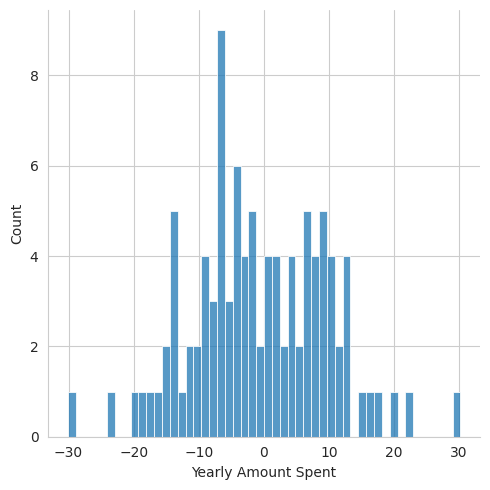

In [27]:
sns.displot((y_test-y_pred), bins=50)
plt.tight_layout()

In [28]:
pd.DataFrame(model.coef_, X.columns, columns=['Coeff'])

,Coeff
Avg. Session Length,25.596259
Time on App,38.785346
Time on Website,0.310386
Length of Membership,61.896829
